# GPU VRAM & Batch Size Capacity Planner (`LLaDA-8B-Instruct` — E1 & E3)

This notebook calculates and benchmarks **how much GPU VRAM and wall-clock compute time** you need for any target `batch_size` when running **MEDAL** and **AB-MEDAL** on the predetermined GSM8K test split ($B \in \{256, 512\}$, $L_c = 10$, $C_{\min} = 3$, 4 configurations total).

It operates in two modes:
1. **Analytical Capacity Planner (Works on CPU or GPU)**: Computes exact `bfloat16` parameter, activation, and dual-logits peak memory at the GSM8K test set's worst-case sequence length ($T_{\max} \approx 850$ tokens), maps each `batch_size` to the minimum safe GPU tier (`L4 22.5 GiB`, `RTX 4090 / A10G 24 GB`, `A100 40 GB`, `L40S / A6000 48 GB`, `A100 / H100 80 GB`), and estimates wall-clock hours for **200 primary** and **500 extended** test questions.
2. **Live Empirical CUDA Sweep (When Attached to a GPU)**: Loads `LLaDA-8B-Instruct` with varlen FlashAttention-2, sweeps candidate `batch_size` values while catching `OutOfMemoryError` safely, and measures empirical `max_memory_allocated`, `max_memory_reserved`, `NFEs/s`, and speedup.

## 1. Workspace & Hardware Detection
Locate the local repository checkout and inspect the attached hardware (CPU or CUDA GPU).

In [1]:
from pathlib import Path
import os
import sys
import torch

REPO_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src/dlm_project").is_dir()),
    Path.cwd(),
)
os.chdir(REPO_DIR)
for p in (str(REPO_DIR), str(REPO_DIR / "src")):
    if p not in sys.path:
        sys.path.insert(0, p)

print(f"Repository Root: {REPO_DIR}")
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    vram_gib = gpu.total_memory / (1024 ** 3)
    print(f"Active CUDA GPU: {gpu.name} | Total VRAM: {vram_gib:.2f} GiB | BF16 Supported: {torch.cuda.is_bf16_supported()}")
else:
    print("No CUDA GPU detected — running in Analytical Capacity Planning mode (CPU).")

Repository Root: /Users/aditya/Documents/USC/CSCI 544 Applied NLP /CSCI544-DLM
No CUDA GPU detected — running in Analytical Capacity Planning mode (CPU).


## 2. Check GPU Requirement for Your Target `BATCH_SIZE`
Set `TARGET_BATCH_SIZE` below (and `BATCH_SIZES_TO_COMPARE`) to see the exact VRAM requirement, recommended GPU tier, and projected runtime for **200 (primary)** and **500 (extended)** GSM8K test questions across all 4 configurations (`medal@256`, `ab_medal@256`, `medal@512`, `ab_medal@512`).

In [2]:
import pandas as pd
from IPython.display import display
from scripts.profile_gpu_batch_size import (
    estimate_vram_and_compute,
    inspect_manifest_token_lengths,
)

# >>> Set the batch_size you want to check <<<
TARGET_BATCH_SIZE = 4
BATCH_SIZES_TO_COMPARE = [1, 2, 4, 6, 8, 12, 16, 24, 32, 48, 64]
if TARGET_BATCH_SIZE not in BATCH_SIZES_TO_COMPARE:
    BATCH_SIZES_TO_COMPARE = sorted([*BATCH_SIZES_TO_COMPARE, TARGET_BATCH_SIZE])

token_stats = inspect_manifest_token_lengths(num_samples=500, gen_length=256)
MAX_SEQ_LEN = max(850, token_stats["max_total_tokens"])

print("=== GSM8K 500-Question Test Manifest Sequence Lengths (Prompt + 256 Gen Tokens) ===")
print(
    f"  Min: {token_stats['min_total_tokens']} | Mean: {token_stats['mean_total_tokens']:.0f} | "
    f"P95: {token_stats['p95_total_tokens']} | P99: {token_stats['p99_total_tokens']} | "
    f"Max: {token_stats['max_total_tokens']} (Safety ceiling T_max = {MAX_SEQ_LEN})"
)

rows = estimate_vram_and_compute(
    batch_sizes=BATCH_SIZES_TO_COMPARE,
    max_seq_len=MAX_SEQ_LEN,
    max_budget=512,
)
target_row = next(r for r in rows if r["batch_size"] == TARGET_BATCH_SIZE)

print("\n" + "=" * 86)
print(f"CAPACITY VERDICT FOR BATCH_SIZE = {TARGET_BATCH_SIZE} (Continuous B=512 w/ B=256 Checkpoint)")
print("=" * 86)
print(f"  Static Model + CUDA Context : {target_row['static_base_gib']:.2f} GiB")
print(f"  Dynamic Batch Activations   : {target_row['dynamic_peak_gib']:.2f} GiB (at T_max = {MAX_SEQ_LEN})")
print(f"  Est. Peak Allocated VRAM    : {target_row['est_peak_allocated_gib']:.2f} GiB")
print(f"  Est. Peak Reserved VRAM     : {target_row['est_peak_reserved_gib']:.2f} GiB (includes allocator safety margin)")
print(f"  Minimum Recommended GPU     : {target_row['recommended_gpu']}")
print(f"  Est. Runtime (200 Primary)  : ~{target_row['est_hours_200q_l4']:.1f} hrs on L4  |  ~{target_row['est_hours_200q_a100']:.1f} hrs on A100")
print(f"  Est. Runtime (500 Extended) : ~{target_row['est_hours_500q_l4']:.1f} hrs on L4  |  ~{target_row['est_hours_500q_a100']:.1f} hrs on A100")
print("=" * 86)

df_plan = pd.DataFrame(rows)[[
    "batch_size",
    "est_peak_allocated_gib",
    "est_peak_reserved_gib",
    "recommended_gpu",
    "fits_l4_22_5gib",
    "fits_24gb_gpu",
    "fits_a100_40gb",
    "fits_80gb_gpu",
    "est_hours_200q_l4",
    "est_hours_500q_l4",
    "est_hours_200q_a100",
    "est_hours_500q_a100",
]]
print("\n=== Full Batch Size vs. GPU Tier Capacity Table ===")
display(df_plan)

=== GSM8K 500-Question Test Manifest Sequence Lengths (Prompt + 256 Gen Tokens) ===
  Min: 542 | Mean: 579 | P95: 625 | P99: 657 | Max: 738 (Safety ceiling T_max = 850)

CAPACITY VERDICT FOR BATCH_SIZE = 4 (Continuous B=512 w/ B=256 Checkpoint)
  Static Model + CUDA Context : 15.80 GiB
  Dynamic Batch Activations   : 2.09 GiB (at T_max = 850)
  Est. Peak Allocated VRAM    : 17.89 GiB
  Est. Peak Reserved VRAM     : 18.67 GiB (includes allocator safety margin)
  Minimum Recommended GPU     : L4 (24GB / 22.5 GiB)
  Est. Runtime (200 Primary)  : ~22.3 hrs on L4  |  ~7.0 hrs on A100
  Est. Runtime (500 Extended) : ~55.7 hrs on L4  |  ~17.4 hrs on A100

=== Full Batch Size vs. GPU Tier Capacity Table ===


,batch_size,est_peak_allocated_gib,est_peak_reserved_gib,recommended_gpu,fits_l4_22_5gib,fits_24gb_gpu,fits_a100_40gb,fits_80gb_gpu,est_hours_200q_l4,est_hours_500q_l4,est_hours_200q_a100,est_hours_500q_a100
0,1,16.41,16.96,L4 (24GB / 22.5 GiB),True,True,True,True,28.87,72.16,11.78,29.46
1,2,16.90,17.53,L4 (24GB / 22.5 GiB),True,True,True,True,25.61,64.03,9.26,23.16
2,4,17.89,18.67,L4 (24GB / 22.5 GiB),True,True,True,True,22.28,55.70,6.98,17.44
3,6,18.87,19.81,L4 (24GB / 22.5 GiB),True,True,True,True,20.74,51.85,5.95,14.88
4,8,19.85,20.95,RTX 3090 / 4090 / A10G (24GB),False,True,True,True,19.95,49.88,5.40,13.50
5,12,21.82,23.23,A100 (40GB),False,False,True,True,19.29,48.24,4.86,12.16
6,16,23.78,25.51,A100 (40GB),False,False,True,True,19.09,47.72,4.64,11.60
7,24,27.71,30.07,A100 (40GB),False,False,True,True,19.00,47.50,4.49,11.23
8,32,31.64,34.62,A100 (40GB),False,False,True,True,18.99,47.48,4.46,11.14
9,48,39.50,43.74,A100 (80GB),False,False,False,True,18.99,47.48,4.45,11.12


## 3. Live Empirical CUDA Benchmark (Optional — Runs Automatically If CUDA GPU Is Active)
When executed on a GPU machine, this cell loads `LLaDA-8B-Instruct` and empirically profiles actual `torch.cuda.max_memory_allocated()`, `torch.cuda.max_memory_reserved()`, and throughput (`NFEs/s`) across `EMPIRICAL_BATCH_SIZES`, catching any OOM cleanly.

In [3]:
from scripts.profile_gpu_batch_size import run_empirical_cuda_sweep
from dlm_project.tasks.gsm8k.experiment_1 import context, load_model

EMPIRICAL_BATCH_SIZES = [1, 2, 4, 6, 8, 12, 16]
empirical_rows = None

if torch.cuda.is_available():
    print("CUDA GPU detected — running live empirical VRAM & throughput sweep...")
    MODEL_PATH = os.environ.get("MODEL_PATH", None)
    ctx_prof = context(stage="test", num_samples=2)
    wrapper_prof = load_model(
        ctx_prof,
        model_path=MODEL_PATH,
        device="cuda",
        local_files_only=bool(MODEL_PATH and Path(MODEL_PATH).is_dir()),
    )
    empirical_rows = run_empirical_cuda_sweep(
        wrapper_prof,
        batch_sizes=EMPIRICAL_BATCH_SIZES,
        max_seq_len=MAX_SEQ_LEN,
        max_budget=512,
    )
    df_emp = pd.DataFrame(empirical_rows)
    display(df_emp)

    ok_rows = [r for r in empirical_rows if r["status"] == "OK" and r["vram_headroom_gib"] >= 1.5]
    if ok_rows:
        best = max(ok_rows, key=lambda r: r["nfes_per_sec"])
        print(
            f"\n✓ Recommended Optimal BATCH_SIZE for this {best['gpu_name']}: "
            f"batch_size = {best['batch_size']} "
            f"(Reserved: {best['peak_reserved_gib']:.2f} GiB / {best['gpu_total_gib']:.2f} GiB, "
            f"Speedup: {best['speedup_vs_b1']:.2f}x, "
            f"200Q: ~{best['est_hours_200q']:.1f}h, 500Q: ~{best['est_hours_500q']:.1f}h)"
        )
else:
    print("Skipping live CUDA sweep (no GPU attached). Analytical projections above are ready for capacity planning.")

Skipping live CUDA sweep (no GPU attached). Analytical projections above are ready for capacity planning.


## 4. Visual GPU VRAM & Runtime Scaling Curves
Plot GPU memory requirements against hardware tier ceilings (`L4 22.5 GiB`, `24 GB`, `A100 40 GB`, `48 GB`, `80 GB`) and projected total runtime for $N = 200$ and $N = 500$ questions.

Saved plot to: /Users/aditya/Documents/USC/CSCI 544 Applied NLP /CSCI544-DLM/results/gpu_batch_size_profile.png


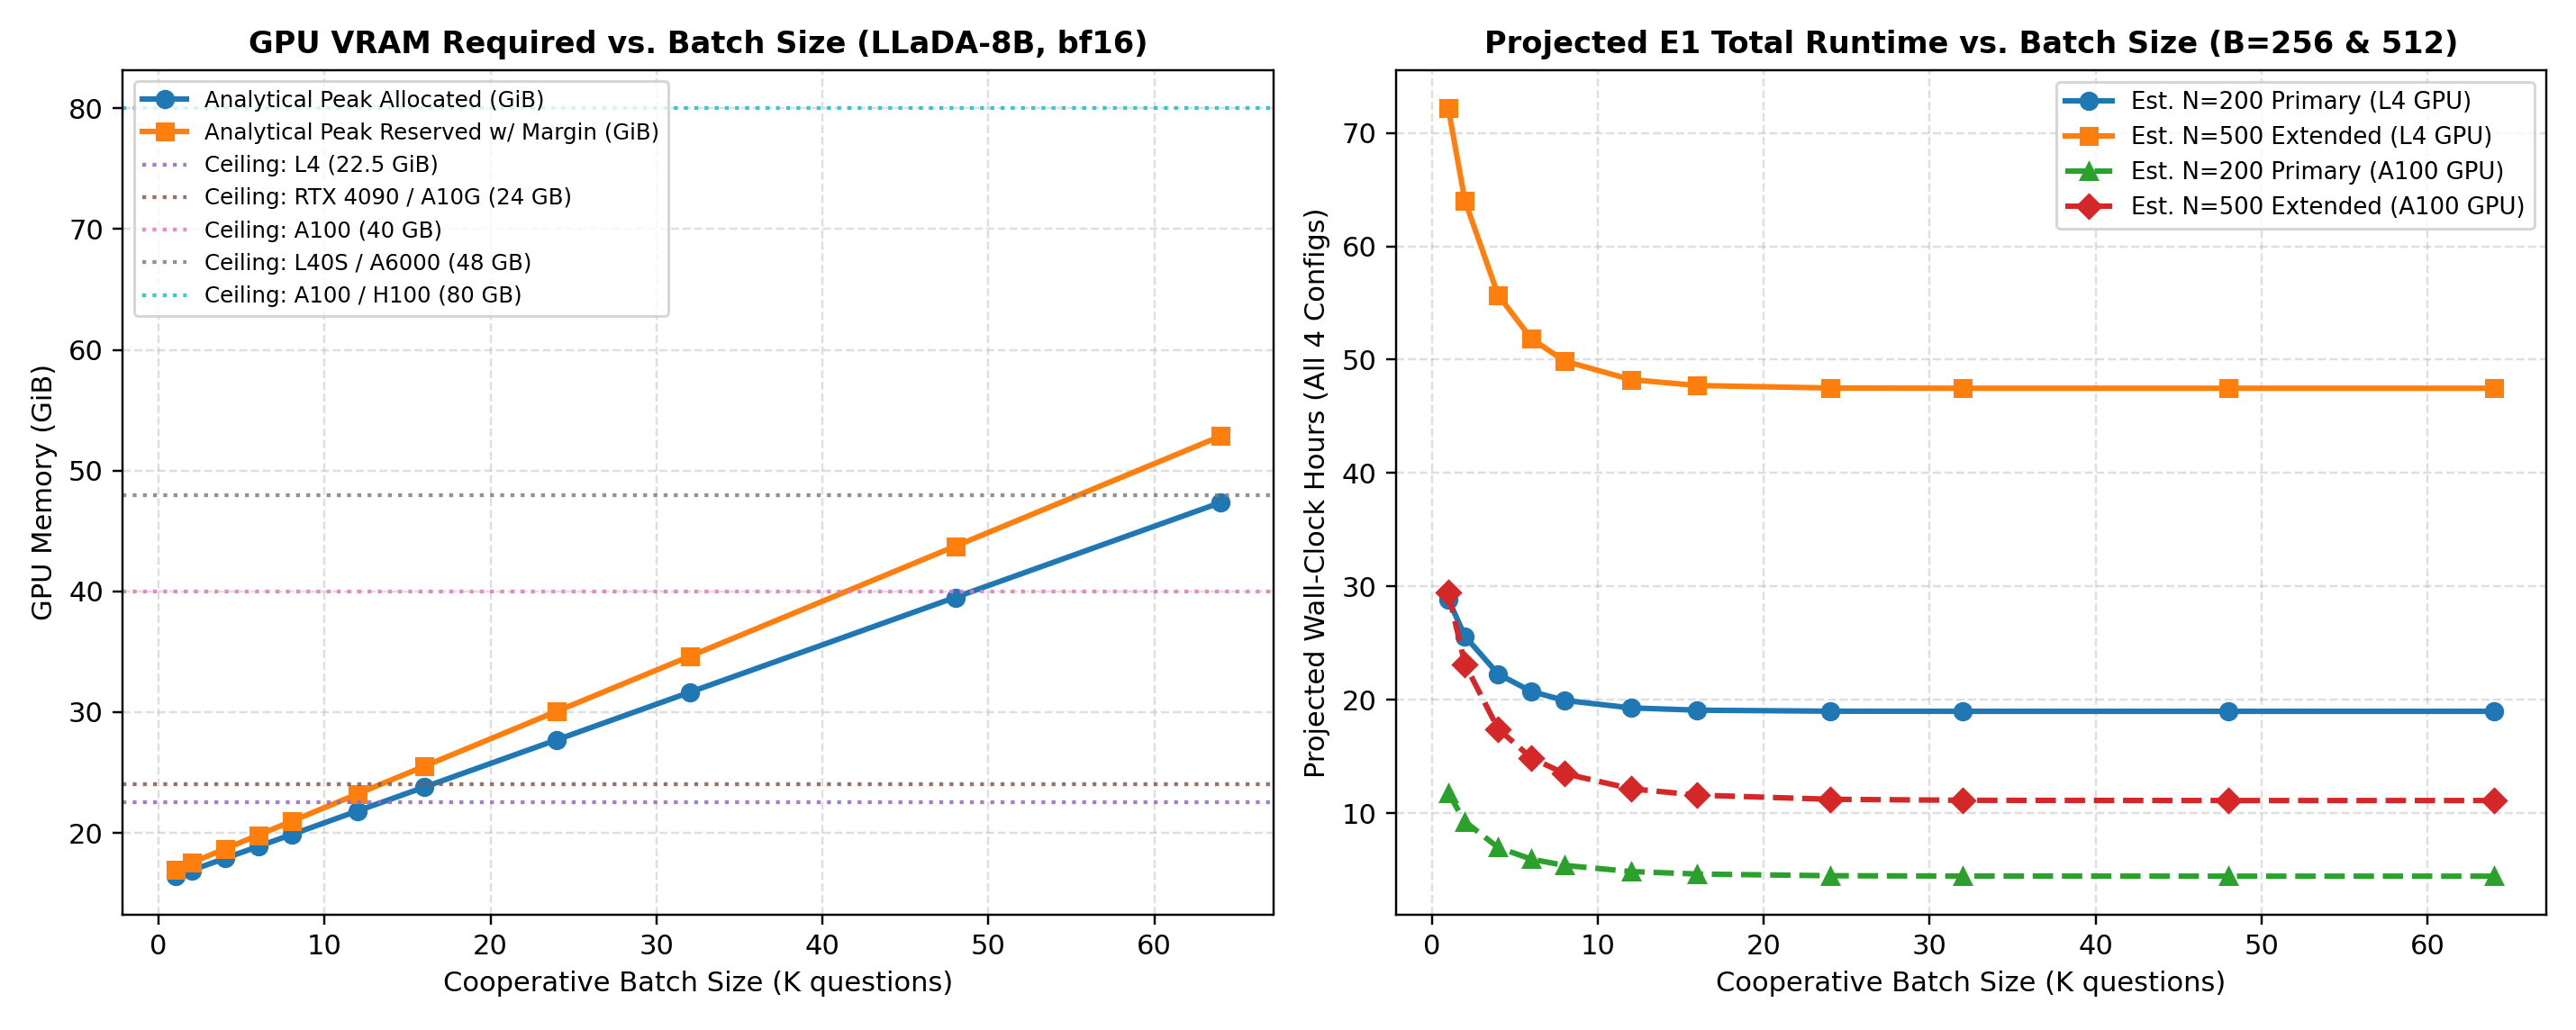

In [4]:
from IPython.display import Image, display
from scripts.profile_gpu_batch_size import plot_gpu_capacity_profile

plot_path = plot_gpu_capacity_profile(
    rows,
    empirical_rows=empirical_rows,
    save_path=REPO_DIR / "results/gpu_batch_size_profile.png",
)
print(f"Saved plot to: {plot_path}")
display(Image(filename=str(plot_path)))